## Quantum Programming (continued)

### Nicolas Ollinger and Ioan Todinca
<img style="width:15%; height: auto;" src="img/lifo.png">

#### M2 Computer Science, S9 2026/2027


## Quantum circuits?

Today’s (or perhaps tomorrow’s?) quantum computers are used as _coprocessors_: one applies a <b class="cool">unitary transformation</b> to a <b class="cool">register of qubits</b> initially all set to zero, and then performs <b class="cool">measurements</b> on its state.

<b class="cool">Unitary transformations</b> are encoded as circuits, and quantum programming looks like <b class="cool">assembly-level programming</b>.

Quantum programming offers a <b class="cool">new form of parallelism</b>.


### Hello Qiskit


In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.providers.basic_provider import BasicProvider
from qiskit_aer import UnitarySimulator
from qiskit.visualization import plot_histogram
import qiskit.quantum_info as qi
from math import sqrt
import numpy as np

# Un simulateur de circuit complet
sim = BasicProvider().get_backend('basic_simulator')

# Un simulateur calculant la matrice de transformation
usim = UnitarySimulator()

# Afficher un circuit
def draw_circ(circ): display(circ.draw(output='mpl'))
    
# Calculer la matrice d'un circuit
def mat_circ(circ): return usim.run(circ).result().get_unitary()

def show(circ):
    draw_circ(circ)
    display(mat_circ(circ).draw('latex'))

# Quantum circuits


### Quantum circuits

A quantum circuit is composed of a fixed number of **wires**; they represent the **qubits** of a finite, discrete quantum system. The **wires** are the **qubits**.

**Quantum gates** apply operations to these states until a final state is obtained.

Only **measurements** of these states provide (partial) information at the output.

All **qubits** are initialised to the value $\left|0\right>$.


### Representations and computations

To reason about circuits and the **unitary transformations** they implement, several tools are available:
 - the matrix representation of circuits (dimension $2^n$ for $n$ qubits!);
 - calculations with Dirac notation $\left<\phi\middle|\psi\right>$;
 - the graphical tools of the ZX‑calculus!


<div style="text-align:center; width: 100%; height: 70%"><img style="margin: auto; width: auto; height: 100%;" src="img/qpic.png"></div>

### A qubit

A <b class="cool">quantum memory</b> register is a <b class="cool">finite discrete quantum system</b> made up of <b class="cool">qubits</b>.

A <b class="cool">quantum bit</b> is a superposition of $0$ and $1$:
$$
\alpha\,\left|0\right> + \beta\,\left|1\right> 
\quad\mbox{with}\quad \alpha, \beta \in \mathbb{C}
\quad\mbox{such that}\quad |\alpha|^2+|\beta|^2 = 1
$$

For example $\left|0\right>$ or $\tfrac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right)$.


### Multiple qubits

A register of <b class="cool">$n$ qubits</b> is a superposition over every bit‑string in $\{0,1\}^n$, each with a complex amplitude.
$$
\left|\varphi\right> = \sum_{x\in\{0,1\}^n} \alpha_x\,\left|x\right>
\quad\mbox{with}\quad \sum_{x\in\{0,1\}^n} |\alpha_x|^2 = 1
$$

For example $\tfrac12\left|1000\right>+\tfrac12\left|0100\right>+\tfrac12\left|0010\right>+\tfrac12\left|0001\right>$


### Tensor product

The <b class="cool">composition</b> of two quantum registers uses the <b class="cool">tensor product</b> $\otimes$, which on basis vectors satisfies $\left|x\right> \otimes \left|y\right> = \left|xy\right>$.

$$
\left|1\right> \otimes \frac{1}{\sqrt{2}}\left(\left|0\right>+\left|1\right>\right) =
\frac{1}{\sqrt{2}}\left(\left|10\right>+\left|11\right>\right)
$$

Unlike the classical case, not every register is decomposable into subregisters! 

Example of an <b class="cool">entangled</b> state: $\tfrac{1}{\sqrt{2}}\left(\left|00\right>+\left|11\right>\right)$.


## Quantum measurement (observation)

<img style="width=100%; height=auto; margin: auto" src="img/mesure.png" />


## Quantum measurement of a specific qubit

Starting from a state $\left|\varphi\right> = \sum_x \alpha_x\,\left|x\right>$, measuring the $i$‑th qubit in the computational ($Z$) basis yields a value $r\in\{0,1\}$ with probability $p_r$, and the system changes state as follows:

$$
\sum_{x\in\{0,1\}^n} \alpha_x\,\left|x\right> \underset{\phantom{blop}p_r\phantom{blop}}{\longrightarrow}
\frac{1}{\sqrt{p_r}} \sum_{x\in\{0,1\}^n \mid x_i = r} \alpha_x\,\left|x\right>
$$

$$
\mbox{with}\quad p_r = \sum_{x\in\{0,1\}^n \mid x_i = r}|\alpha_x|^2
$$


## Unitary evolution

In the absence of measurement, when isolated, the state of a quantum system evolves <b class="cool">unitarily</b>.

$$
U : \mathbb{C}^{\{0,1\}^n} \rightarrow \mathbb{C}^{\{0,1\}^n}
$$

1. $U$ is linear:
$$
U\left(\alpha\left|\varphi\right>+\beta\left|\psi\right>\right) = \alpha\,U\left|\varphi\right>+\beta\,U\left|\psi\right>\quad;
$$
2. $U$ preserves the norm: $\left\| U\left|\varphi\right> \right\| = \left\| \left|\varphi\right> \right\|$.


## Quantum gate

A quantum circuit encodes a <b class="cool">unitary transformation</b> applied to a quantum state. Quantum gates are therefore reversible, with as many qubits at input as at output.
- sequential composition: matrix product;
- parallel composition: tensor product.


## Single-qubit gates

$$
\begin{array}{clclcl}
X :& \left|0\right> \mapsto \left|1\right> & H :& \left|0\right> \mapsto \tfrac{\left|0\right>+\left|1\right>}{\sqrt2}  & R_\theta :& \left|0\right> \mapsto \left|0\right>\\
   & \left|1\right> \mapsto \left|0\right> &    & \left|1\right> \mapsto \tfrac{\left|0\right>-\left|1\right>}{\sqrt2} &  & \left|1\right> \mapsto e^{i\theta}\left|1\right> \\
\end{array}
$$


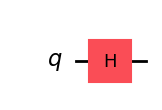

<IPython.core.display.Latex object>

In [2]:
from math import pi
circuit = QuantumCircuit(1)
# here replace x with h or t (=r(pi/4)) or sx (sqrt(x))
circuit.h(0) 
show(circuit)

## Controlled gates

$$
\begin{array}{cl}
\mathrm{CX} :& \left|00\right> \mapsto \left|00\right> \\
   & \left|01\right> \mapsto \left|01\right> \\
   & \left|10\right> \mapsto \left|11\right> \\
   & \left|11\right> \mapsto \left|10\right> \\
\end{array}
$$


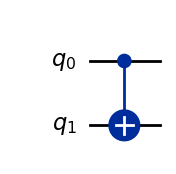

<IPython.core.display.Latex object>

In [18]:
circuit = QuantumCircuit(2)
circuit.cx(0,1)
show(circuit)

# Warm-up

## What does that circuit compute?

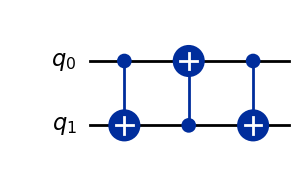

In [3]:
circuit = QuantumCircuit(2)
circuit.cx(0,1)
circuit.cx(1,0)
circuit.cx(0,1)
draw_circ(circuit)

## Routing

The Quito processor can perform single-qubit gates and CX (controlled-X) gates on two qubits. This gate set is universal.

<div style="width:100%">
<img style="display:inline; width:45%; height: auto;" src="img/quito2.png">
<img style="display:inline; width:45%; height: auto;" src="img/quito3.png">
</div>

How can we modify a complex circuit that needs to perform a CX between qubits 0 and 4? What is the cost?



# Hadamard gate

## Hadamard gate

The Hadamard gate ($H$), on 1 qubit, is a basis‑change gate.

$$
\begin{array}{clllll}
H :& \left|0\right> &\mapsto &\left|+\right> & = &\tfrac{\left|0\right>+\left|1\right>}{\sqrt2} \\
   & \left|1\right> &\mapsto &\left|-\right> & = &\tfrac{\left|0\right>-\left|1\right>}{\sqrt2}  \\
\end{array}
$$

In theory, adding this gate to the Toffoli gate yields universality for unitary transformations (i.e., any quantum circuit).

_In practice this is not very efficient; we proceed differently._


## Exercise

Study this circuit on input $\left|00\right>$.


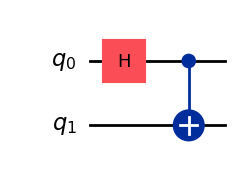

In [17]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.cx(0,1)
draw_circ(circuit)

## Properties

$$
\begin{array}{rl}
H \cdot H &= \text{Id}\\
H : \quad\left|x\right> &\mapsto \tfrac1{\sqrt 2}\sum_{y\in\{0,1\}} (-1)^{xy} \left|y\right>\\
H^{\otimes n} : \quad\left|x\right> &\mapsto \tfrac1{\sqrt {2^n}}\sum_{y\in\{0,1\}^n} (-1)^{x\bullet y} \left|y\right> \qquad\text{with } x\bullet y = \bigoplus_i x_i y_i
\end{array}
$$


## Exercise

1. Compute $H^{\otimes n} \left( \left|0\right>^{\otimes n}\right)$

2. Study this circuit


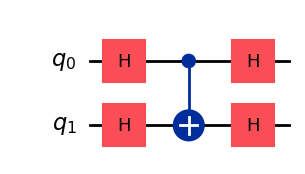

In [11]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.h(1)
circuit.cx(0,1)
circuit.h(0)
circuit.h(1)
draw_circ(circuit)

## Computer‑assisted verification


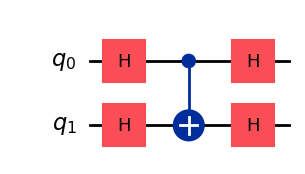

<IPython.core.display.Latex object>

In [4]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.h(1)
circuit.cx(0,1)
circuit.h(0)
circuit.h(1)
show(circuit)

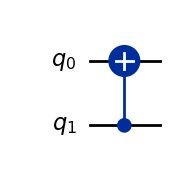

<IPython.core.display.Latex object>

In [5]:
circuit = QuantumCircuit(2)
circuit.cx(1,0)
show(circuit)

## Oracle

For any function $f : \{0,1\}^n \rightarrow \{0,1\}$, we have seen that there exists a quantum circuit with $n+1$ data qubits (plus ancilla qubits) which, on input $\left|x\right>\otimes\left|y\right>$, computes $\left|x\right>\otimes\left|y \oplus f(x)\right>$.

Show that by adding an $X$ gate and an $H$ gate before and after the circuit on the $\left|y\right>$ wire, one obtains a **phase oracle** that, on input $\left|x\right>$, computes $(-1)^{f(x)}\,\left|x\right>$, using an ancilla qubit initialised to $\left|0\right>$.


# Bernstein–Vazirani algorithm 


## Doing better with quantum?

<b class="cool">Quantum algorithms</b> outperform classical algorithms on some problems, sometimes dramatically:
- integer factorisation (Shor);
- searching for an element in an unsorted list (Grover);
- ...

Let’s look at a simple example together.


## Bernstein–Vazirani

This algorithm is of the <b class="cool">black‑box</b> type.

We suppose we have a classical circuit which, on input $x\in\{0,1\}^n$, computes a function $f(x)=x\odot s$ for some unknown mask $s\in\{0,1\}^n$, where $x\odot s = x_1 s_1 \oplus x_2 s_2 \oplus \cdots \oplus x_n s_n$.

The goal is to recover $s$ with as few calls to $f$ as possible.

A quick information‑theoretic argument shows that any classical algorithm needs to call $f$ at least $n$ times to recover $s$ (and can then always succeed).


## Bernstein–Vazirani (continued)

The quantum algorithm proposed by Bernstein and Vazirani recovers $s$ with a single call to $f$!

We suppose we have a quantum circuit which, on input $(x,y)\in\{0,1\}^{n+1}$, computes the value $x \otimes (y \oplus x\odot s)$.

Let’s build a circuit that illustrates this algorithm!


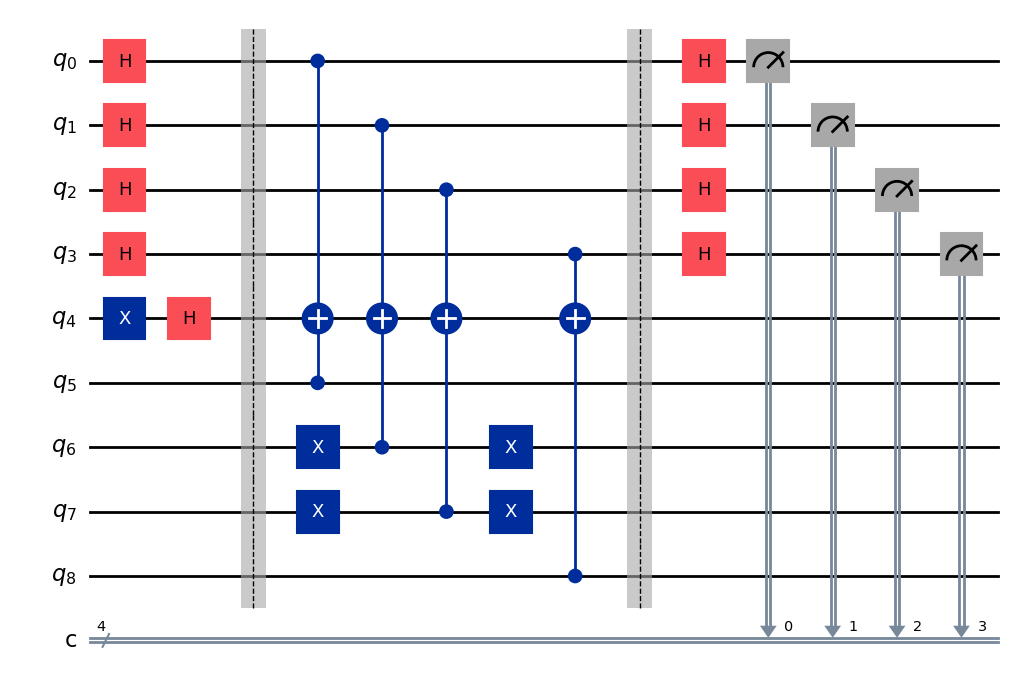

{'0110': 1}


In [6]:
s = '0110'
k = len(s)

circuit = QuantumCircuit(2*k+1,k)
 
# superposition
circuit.x(k)
for i in range(k+1):
    circuit.h(i)
circuit.barrier()
# parallel computation
for i in range(k):
    if s[i] == '1':
        circuit.x(k+1+i)

for i in range(k):
    circuit.ccx(i,k+1+i,k)

for i in range(k):
    if s[i] == '1':
        circuit.x(k+1+i)
circuit.barrier()
# quantum transformation
for i in range(k):
    circuit.h(i)
# measure
circuit.measure(list(range(k)), list(range(k)))

display(circuit.draw(output='mpl',scale=1))
res = sim.run(circuit, shots=1).result()
print(res.get_counts(circuit))


## Run remotely


### Run the code on a quantum processor

What is the difference between our simulator and the real world?

Let’s modify the example into an equivalent circuit so it fits on fewer qubits and is a bit more robust to noise.

Let’s look at the obtained result and the executed circuit.


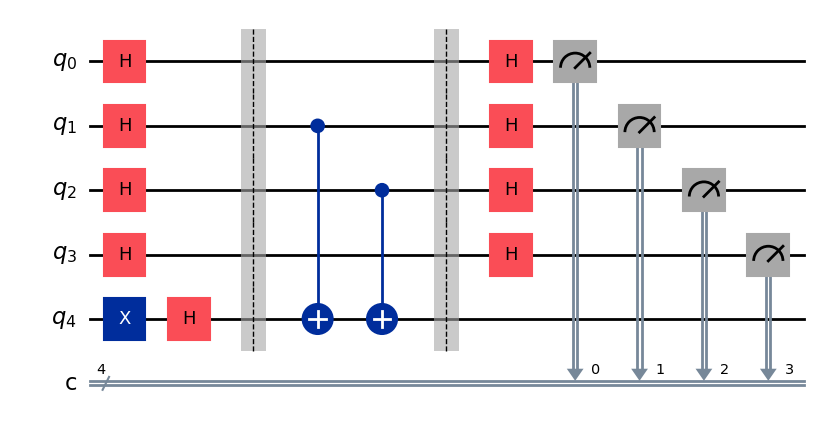

{'0110': 1}


In [7]:
s = '0110'
k = len(s)

circuit = QuantumCircuit(k+1,k)

circuit.x(k)
for i in range(k+1):
    circuit.h(i)
circuit.barrier()

for i in range(k):
    if s[i] == '1':
        circuit.cx(i,k)
circuit.barrier()

for i in range(k):
    circuit.h(i)
    
circuit.measure(list(range(k)), list(range(k)))

display(circuit.draw(output='mpl',scale=1))
res = sim.run(circuit, shots=1).result()
print(res.get_counts(circuit))


In [8]:
from qiskit_ibm_runtime import QiskitRuntimeService
 
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=5)

# Get the least busy real quantum system
print(backend, backend.status().pending_jobs)

<IBMBackend('ibm_sherbrooke')> 20


<img style="width:100%; height: auto;" src="img/sherbrooke1.png">

<img style="width:100%; height: auto;" src="img/sherbrooke2.png">

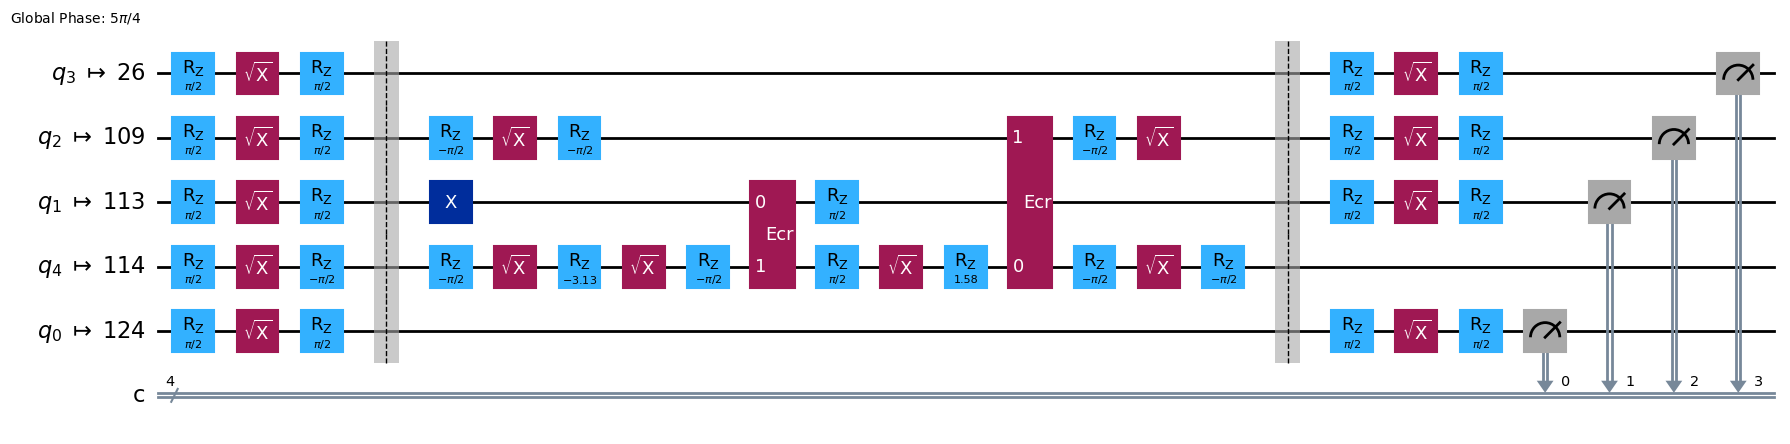

In [7]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

circuit_isa = pm.run(circuit)
circuit_isa.draw(output="mpl", idle_wires=False, style="iqp")

In [44]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(backend)
sampler.options.default_shots = 10_000
result = sampler.run([circuit_isa]).result()

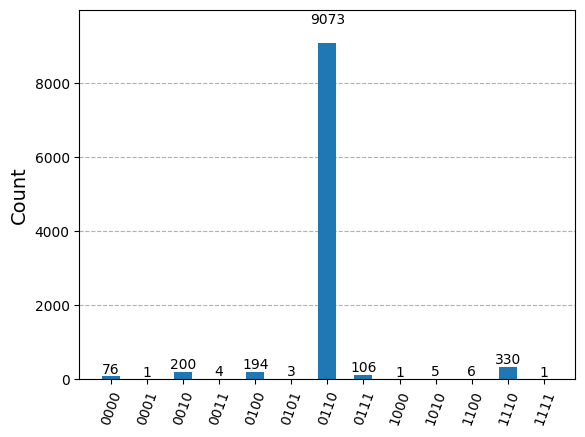

In [45]:
plot_histogram(result[0].data.c.get_counts())

# Proof

## by calculation and combinatorics
